In [ ]:
# Packages for numerics + dataframes
import pandas as pd
import numpy as np

# Packages for visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Packages for Logistic Regression & Confusion Matrix
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import (
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# This is the function that helps plot feature importance
from xgboost import plot_importance

# This module lets us save our models once we fit them.
import pickle


In [104]:
df = pd.read_csv("data/processed/waze_dataset.csv")

In [105]:
df.isnull().sum()

Unnamed: 0                          0
ID                                  0
label                             700
sessions                            0
drives                              0
total_sessions                      0
n_days_after_onboarding             0
total_navigations_fav1              0
total_navigations_fav2              0
driven_km_drives                    0
duration_minutes_drives             0
activity_days                       0
driving_days                        0
device                              0
km_per_driving_day                  0
drives_per_driving_day              7
percent_sessions_in_last_month      0
device_type                         0
dtype: int64

In [106]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14999 entries, 0 to 14998
Data columns (total 18 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Unnamed: 0                      14999 non-null  int64  
 1   ID                              14999 non-null  int64  
 2   label                           14299 non-null  object 
 3   sessions                        14999 non-null  int64  
 4   drives                          14999 non-null  int64  
 5   total_sessions                  14999 non-null  float64
 6   n_days_after_onboarding         14999 non-null  int64  
 7   total_navigations_fav1          14999 non-null  int64  
 8   total_navigations_fav2          14999 non-null  int64  
 9   driven_km_drives                14999 non-null  float64
 10  duration_minutes_drives         14999 non-null  float64
 11  activity_days                   14999 non-null  int64  
 12  driving_days                    

In [107]:
df.describe()

c:\Users\Sarvamm\AppData\Local\Programs\Python\Python312\Lib\site-packages\pandas\core\nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)


,Unnamed: 0,ID,sessions,drives,total_sessions,n_days_after_onboarding,total_navigations_fav1,total_navigations_fav2,driven_km_drives,duration_minutes_drives,activity_days,driving_days,km_per_driving_day,drives_per_driving_day,percent_sessions_in_last_month,device_type
count,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,1.499200e+04,14999.000000,14999.000000
mean,7499.000000,7499.000000,76.568705,64.058204,184.031320,1749.837789,121.605974,29.672512,3939.632764,1789.647426,15.537102,12.179879,578.963113,inf,0.449255,1.355157
std,4329.982679,4329.982679,67.297958,55.306924,118.600463,1008.513876,148.121544,45.394651,2216.041510,1222.705167,9.004655,7.824036,1030.094384,NaN,0.286919,0.478577
min,0.000000,0.000000,0.000000,0.000000,0.220211,4.000000,0.000000,0.000000,60.441250,18.282082,0.000000,0.000000,0.000000,0.000000e+00,0.000000,1.000000
25%,3749.500000,3749.500000,23.000000,20.000000,90.661156,878.000000,9.000000,0.000000,2212.600607,835.996260,8.000000,5.000000,136.238895,1.800000e+00,0.196221,1.000000
50%,7499.000000,7499.000000,56.000000,48.000000,159.568115,1741.000000,71.000000,9.000000,3493.858085,1478.249859,16.000000,12.000000,272.889272,4.666667e+00,0.423097,1.000000
75%,11248.500000,11248.500000,112.000000,93.000000,254.192341,2623.500000,178.000000,43.000000,5289.861262,2464.362632,23.000000,19.000000,558.686918,1.216667e+01,0.687216,2.000000
max,14998.000000,14998.000000,243.000000,201.000000,454.363204,3500.000000,1236.000000,415.000000,8889.794236,4668.899349,31.000000,30.000000,15420.234110,inf,1.530637,2.000000


In [108]:
df.columns

Index(['Unnamed: 0', 'ID', 'label', 'sessions', 'drives', 'total_sessions',
       'n_days_after_onboarding', 'total_navigations_fav1',
       'total_navigations_fav2', 'driven_km_drives', 'duration_minutes_drives',
       'activity_days', 'driving_days', 'device', 'km_per_driving_day',
       'drives_per_driving_day', 'percent_sessions_in_last_month',
       'device_type'],
      dtype='object')

In [109]:
df["professional_driver"] = np.where(
    (df["drives"] >= 60) & (df["driving_days"] >= 15), 1, 0
)

In [110]:
print(df["professional_driver"].value_counts())

# 2. Check in-class churn rate
df.groupby(["professional_driver"])["label"].value_counts(normalize=True)

professional_driver
0    12405
1     2594
Name: count, dtype: int64


professional_driver  label   
0                    retained    0.801202
                     churned     0.198798
1                    retained    0.924437
                     churned     0.075563
Name: proportion, dtype: float64

In [111]:
df = df.dropna(subset=["label"])

In [112]:
df["label"] = np.where(df["label"] == "churned", 1, 0)

In [113]:
df = df.iloc[:, 1:]

In [114]:
df

,ID,label,sessions,drives,total_sessions,n_days_after_onboarding,total_navigations_fav1,total_navigations_fav2,driven_km_drives,duration_minutes_drives,activity_days,driving_days,device,km_per_driving_day,drives_per_driving_day,percent_sessions_in_last_month,device_type,professional_driver
0,0,0,243,201,296.748273,2276,208,0,2628.845068,1985.775061,28,19,Android,138.360267,11.894737,0.953670,2,1
1,1,0,133,107,326.896596,1225,19,64,8889.794236,3160.472914,13,11,iPhone,1246.901868,9.727273,0.406856,1,0
2,2,0,114,95,135.522926,2651,0,0,3059.148818,1610.735904,14,8,Android,382.393602,11.875000,0.841186,2,0
3,3,0,49,40,67.589221,15,322,7,913.591123,587.196542,7,3,iPhone,304.530374,13.333333,0.724968,1,0
4,4,0,84,68,168.247020,1562,166,5,3950.202008,1219.555924,27,18,Android,219.455667,3.777778,0.499266,2,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14994,14994,0,60,55,207.875622,140,317,0,2890.496901,2186.155708,25,17,iPhone,170.029229,3.235294,0.288634,1,0
14995,14995,0,42,35,187.670313,2505,15,10,4062.575194,1208.583193,25,20,Android,203.128760,1.750000,0.223797,2,0
14996,14996,0,243,201,422.017241,1873,17,0,3097.825028,1031.278706,18,17,iPhone,182.225002,12.882353,0.646893,1,1
14997,14997,1,149,120,180.524184,3150,45,0,4051.758549,254.187763,6,6,iPhone,675.293092,20.000000,0.825374,1,0


In [115]:
corr = df.corr(numeric_only=True)

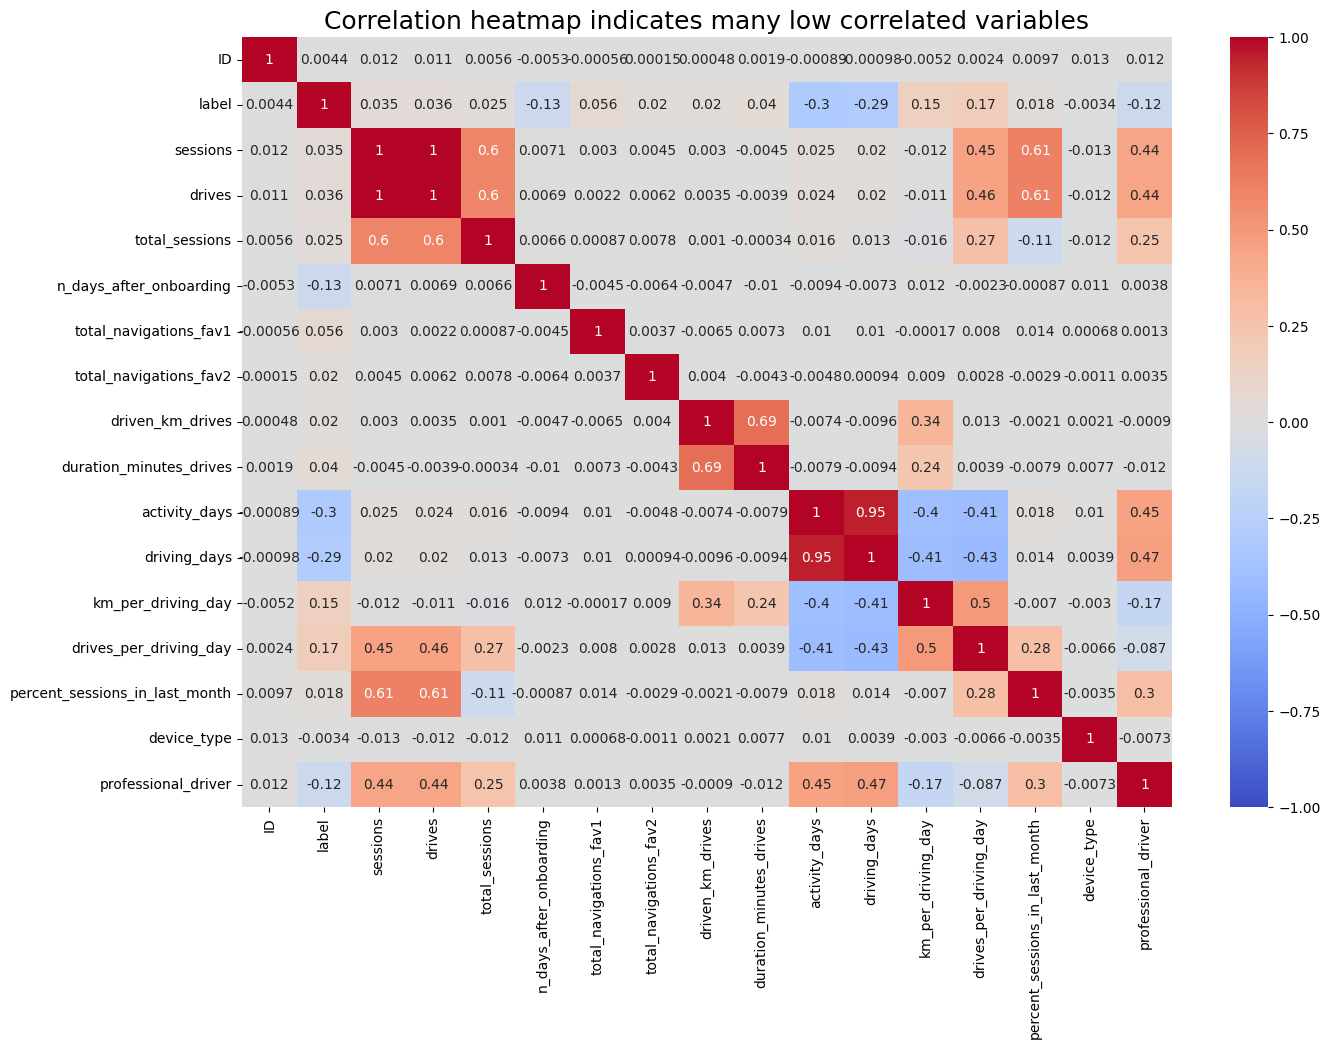

In [116]:
plt.figure(figsize=(15, 10))
sns.heatmap(corr, vmin=-1, vmax=1, annot=True, cmap="coolwarm")
plt.title("Correlation heatmap indicates many low correlated variables", fontsize=18)
plt.show();

In [117]:
df["device"] = np.where(df["device"] == "Android", 0, 1)

In [ ]:
X = df.drop(
    columns=["label", "device", "sessions", "driving_days", "drives_per_driving_day"]
)

In [119]:
y = df["label"]

In [120]:
# Perform the train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, random_state=42)

In [121]:
model = LogisticRegression(max_iter=400)

model.fit(X_train, y_train)

c:\Users\Sarvamm\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 400 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=400).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,400
,multi_class,'deprecated'


In [122]:
pd.Series(model.coef_[0], index=X.columns)

ID                                0.000004
drives                            0.001971
total_sessions                    0.000331
n_days_after_onboarding          -0.000402
total_navigations_fav1            0.001056
total_navigations_fav2            0.001205
driven_km_drives                 -0.000013
duration_minutes_drives           0.000109
activity_days                    -0.105656
km_per_driving_day                0.000019
percent_sessions_in_last_month   -0.011664
device_type                      -0.030377
professional_driver              -0.002458
dtype: float64

In [123]:
training_probabilities = model.predict_proba(X_train)
training_probabilities

array([[0.94014097, 0.05985903],
       [0.61906349, 0.38093651],
       [0.76460961, 0.23539039],
       ...,
       [0.92017615, 0.07982385],
       [0.85056863, 0.14943137],
       [0.93088027, 0.06911973]])

In [124]:
# 1. Copy the `X_train` dataframe and assign to `logit_data`
logit_data = X_train.copy()

# 2. Create a new `logit` column in the `logit_data` df
logit_data["logit"] = [np.log(prob[1] / prob[0]) for prob in training_probabilities]

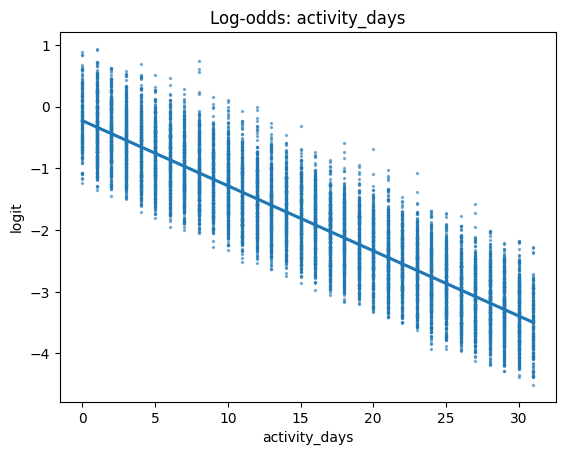

In [125]:
sns.regplot(
    x="activity_days", y="logit", data=logit_data, scatter_kws={"s": 2, "alpha": 0.5}
)
plt.title("Log-odds: activity_days");

In [126]:
y_preds = model.predict(X_test)

In [127]:
model.score(X_test, y_test)

0.8257342657342658

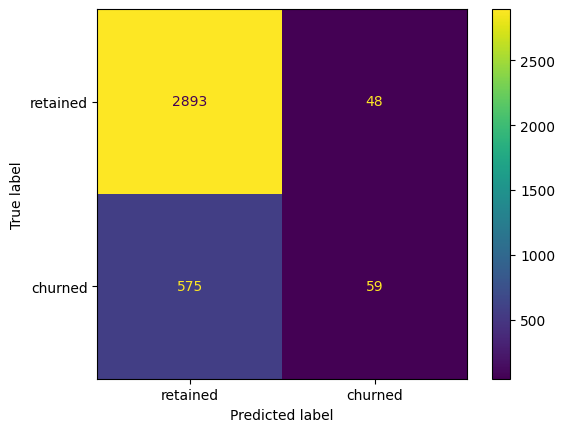

In [128]:
cm = confusion_matrix(y_test, y_preds)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["retained", "churned"],
)
disp.plot();

In [129]:
target_labels = ["retained", "churned"]
print(classification_report(y_test, y_preds, target_names=target_labels))

              precision    recall  f1-score   support

    retained       0.83      0.98      0.90      2941
     churned       0.55      0.09      0.16       634

    accuracy                           0.83      3575
   macro avg       0.69      0.54      0.53      3575
weighted avg       0.78      0.83      0.77      3575



In [ ]:
# Create `total_sessions_per_day` feature
df["total_sessions_per_day"] = df["total_sessions"] / df["n_days_after_onboarding"]

In [ ]:
df["km_per_hour"] = df["driven_km_drives"] / (df["duration_minutes_drives"] / 60)

In [ ]:
df["km_per_drive"] = df["driven_km_drives"] / df["drives"]

In [ ]:
df.loc[df["km_per_drive"] == np.inf, "km_per_drive"] = 0

In [ ]:
# Create `percent_of_sessions_to_favorite` feature
df["percent_of_drives_to_favorite"] = (
    df["total_navigations_fav1"] + df["total_navigations_fav2"]
) / df["total_sessions"]

In [ ]:
df = df.drop("drives_per_driving_day", axis=1)

In [ ]:
df = df.drop("ID", axis=1)

In [ ]:
# 1. Isolate X variables
X = df.drop(columns=["label"])

# 2. Isolate y variable
y = df["label"]

# 3. Split into train and test sets
X_tr, X_test, y_tr, y_test = train_test_split(
    X, y, stratify=y, test_size=0.2, random_state=42
)

# 4. Split into train and validate sets
X_train, X_val, y_train, y_val = train_test_split(
    X_tr, y_tr, stratify=y_tr, test_size=0.25, random_state=42
)

In [149]:
# 1. Instantiate the random forest classifier
rf = RandomForestClassifier(random_state=42)

# 2. Create a dictionary of hyperparameters to tune
cv_params = {
    "max_depth": [None],
    "max_features": [1.0],
    "max_samples": [1.0],
    "min_samples_leaf": [2],
    "min_samples_split": [2],
    "n_estimators": [300],
}

# 3. Define a list of scoring metrics to capture
scoring = ["accuracy", "precision", "recall", "f1"]

# 4. Instantiate the GridSearchCV object
rf_cv = GridSearchCV(rf, cv_params, scoring=scoring, cv=4, refit="recall", n_jobs=-1)

In [150]:
%%time
rf_cv.fit(X_train, y_train)

CPU times: total: 34.7 s
Wall time: 1min 18s


,estimator,RandomForestC...ndom_state=42)
,param_grid,"{'max_depth': [None], 'max_features': [1.0], 'max_samples': [1.0], 'min_samples_leaf': [2], ...}"
,scoring,"['accuracy', 'precision', ...]"
,n_jobs,-1
,refit,'recall'
,cv,4
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,n_estimators,300


In [ ]:
def make_results(model_name: str, model_object, metric: str):
    """
    Arguments:
        model_name (string): what you want the model to be called in the output table
        model_object: a fit GridSearchCV object
        metric (string): precision, recall, f1, or accuracy

    Returns a pandas df with the F1, recall, precision, and accuracy scores
    for the model with the best mean 'metric' score across all validation folds.
    """

    # Create dictionary that maps input metric to actual metric name in GridSearchCV
    metric_dict = {
        "precision": "mean_test_precision",
        "recall": "mean_test_recall",
        "f1": "mean_test_f1",
        "accuracy": "mean_test_accuracy",
    }

    # Get all the results from the CV and put them in a df
    cv_results = pd.DataFrame(model_object.cv_results_)

    # Isolate the row of the df with the max(metric) score
    best_estimator_results = cv_results.iloc[
        cv_results[metric_dict[metric]].idxmax(), :
    ]

    # Extract accuracy, precision, recall, and f1 score from that row
    f1 = best_estimator_results.mean_test_f1
    recall = best_estimator_results.mean_test_recall
    precision = best_estimator_results.mean_test_precision
    accuracy = best_estimator_results.mean_test_accuracy

    # Create table of results
    table = pd.DataFrame(
        {
            "model": [model_name],
            "precision": [precision],
            "recall": [recall],
            "F1": [f1],
            "accuracy": [accuracy],
        },
    )

    return table

In [ ]:
results = make_results("RF cv", rf_cv, "recall")
results

,model,precision,recall,F1,accuracy
0,RF cv,0.454262,0.12022,0.190077,0.818393


In [154]:
# 1. Instantiate the XGBoost classifier
xgb = XGBClassifier(objective="binary:logistic", random_state=42)

# 2. Create a dictionary of hyperparameters to tune
cv_params = {
    "max_depth": [6, 12],
    "min_child_weight": [3, 5],
    "learning_rate": [0.01, 0.1],
    "n_estimators": [300],
}

# 3. Define a list of scoring metrics to capture
scoring = ["accuracy", "precision", "recall", "f1"]

# 4. Instantiate the GridSearchCV object
xgb_cv = GridSearchCV(xgb, cv_params, scoring=scoring, cv=4, refit="recall", n_jobs=-1)

In [155]:
%%time
xgb_cv.fit(X_train, y_train)

CPU times: total: 14.7 s
Wall time: 23 s


,estimator,"XGBClassifier...ree=None, ...)"
,param_grid,"{'learning_rate': [0.01, 0.1], 'max_depth': [6, 12], 'min_child_weight': [3, 5], 'n_estimators': [300]}"
,scoring,"['accuracy', 'precision', ...]"
,n_jobs,-1
,refit,'recall'
,cv,4
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,objective,'binary:logistic'


In [ ]:
# Call 'make_results()' on the GridSearch object
xgb_cv_results = make_results("XGB cv", xgb_cv, "recall")
results = pd.concat([results, xgb_cv_results], axis=0)
results

,model,precision,recall,F1,accuracy
0,RF cv,0.454262,0.120220,0.190077,0.818393
0,XGB cv,0.411819,0.169516,0.240045,0.809652


In [157]:
# Use random forest model to predict on validation data
rf_val_preds = rf_cv.best_estimator_.predict(X_val)

In [ ]:
def get_test_scores(model_name: str, preds, y_test_data):
    """
    Generate a table of test scores.

    In:
        model_name (string): Your choice: how the model will be named in the output table
        preds: numpy array of test predictions
        y_test_data: numpy array of y_test data

    Out:
        table: a pandas df of precision, recall, f1, and accuracy scores for your model
    """
    accuracy = accuracy_score(y_test_data, preds)
    precision = precision_score(y_test_data, preds)
    recall = recall_score(y_test_data, preds)
    f1 = f1_score(y_test_data, preds)

    table = pd.DataFrame(
        {
            "model": [model_name],
            "precision": [precision],
            "recall": [recall],
            "F1": [f1],
            "accuracy": [accuracy],
        }
    )

    return table

In [ ]:
# Get validation scores for RF model
rf_val_scores = get_test_scores("RF val", rf_val_preds, y_val)

# Append to the results table
results = pd.concat([results, rf_val_scores], axis=0)
results

,model,precision,recall,F1,accuracy
0,RF cv,0.454262,0.120220,0.190077,0.818393
0,XGB cv,0.411819,0.169516,0.240045,0.809652
0,RF val,0.441860,0.112426,0.179245,0.817483


In [ ]:
# Use XGBoost model to predict on validation data
xgb_val_preds = xgb_cv.best_estimator_.predict(X_val)

# Get validation scores for XGBoost model
xgb_val_scores = get_test_scores("XGB val", xgb_val_preds, y_val)

# Append to the results table
results = pd.concat([results, xgb_val_scores], axis=0)
results

,model,precision,recall,F1,accuracy
0,RF cv,0.454262,0.120220,0.190077,0.818393
0,XGB cv,0.411819,0.169516,0.240045,0.809652
0,RF val,0.441860,0.112426,0.179245,0.817483
0,XGB val,0.401869,0.169625,0.238558,0.808042


In [ ]:
# Use XGBoost model to predict on test data
xgb_test_preds = xgb_cv.best_estimator_.predict(X_test)

# Get test scores for XGBoost model
xgb_test_scores = get_test_scores("XGB test", xgb_test_preds, y_test)

# Append to the results table
results = pd.concat([results, xgb_test_scores], axis=0)
results

,model,precision,recall,F1,accuracy
0,RF cv,0.454262,0.120220,0.190077,0.818393
0,XGB cv,0.411819,0.169516,0.240045,0.809652
0,RF val,0.441860,0.112426,0.179245,0.817483
0,XGB val,0.401869,0.169625,0.238558,0.808042
0,XGB test,0.377119,0.175542,0.239569,0.802448


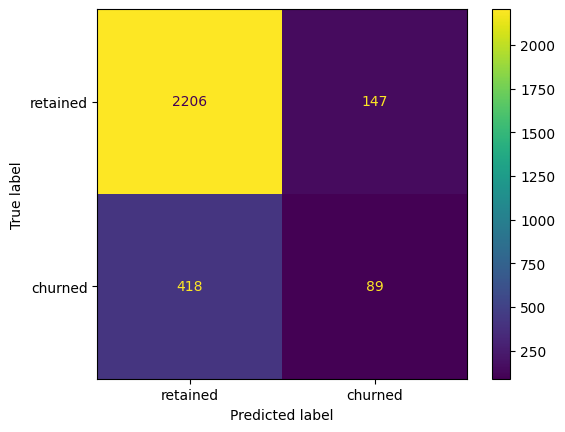

In [ ]:
# Generate array of values for confusion matrix
cm = confusion_matrix(y_test, xgb_test_preds, labels=xgb_cv.classes_)

# Plot confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm, display_labels=["retained", "churned"]
)
disp.plot();

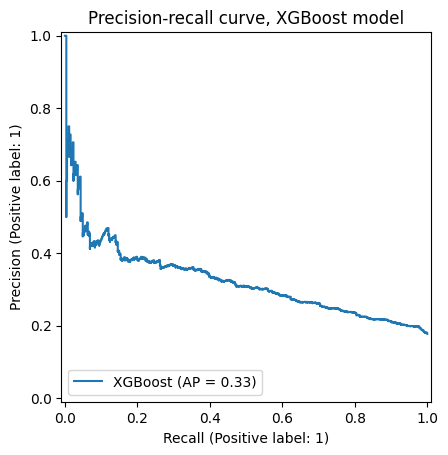

In [165]:
# Plot precision-recall curve
display = PrecisionRecallDisplay.from_estimator(
    xgb_cv.best_estimator_, X_test, y_test, name="XGBoost"
)
plt.title("Precision-recall curve, XGBoost model");

In [167]:
predicted_probabilities = xgb_cv.best_estimator_.predict_proba(X_test)
predicted_probabilities

array([[0.98861283, 0.01138716],
       [0.643669  , 0.35633096],
       [0.9950396 , 0.0049604 ],
       ...,
       [0.886256  , 0.11374405],
       [0.96019953, 0.03980047],
       [0.6225101 , 0.37748992]], dtype=float32)

In [168]:
probs = [x[1] for x in predicted_probabilities]

# Create an array of new predictions that assigns a 1 to any value >= 0.4
new_preds = np.array([1 if x >= 0.4 else 0 for x in probs])
new_preds

array([0, 0, 0, ..., 0, 0, 0])

In [ ]:
# Get evaluation metrics for when the threshold is 0.4
get_test_scores("XGB, threshold = 0.4", new_preds, y_test)

,model,precision,recall,F1,accuracy
0,"XGB, threshold = 0.4",0.38,0.262327,0.310385,0.793357


In [ ]:
# save model
with open("model.pkl", "wb") as f:
    pickle.dump(xgb_cv.best_estimator_, f)